In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    return cutDataframe

In [3]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

# Hadron-level default

In [4]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m']

In [5]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_50pthat1000_rc_truth.txt']

In [6]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
df = pd.concat([df for df in df_array])

In [7]:
df = applyCut(df, 'pt>20')

In [8]:
np.unique(df['parton'])

array([-5, -4, -3, -2, -1,  0,  1,  2,  3,  4,  5, 21])

In [35]:
for parton in np.unique(df['parton']):
    prob = sum(df[df.parton==parton]['w'])/sum(df['w'])
    print('parton, prob:', parton, prob)

parton, prob: -5 0.001558927125149174
parton, prob: -4 0.017781586608439332
parton, prob: -3 0.0048659748347895234
parton, prob: -2 0.019584710801793376
parton, prob: -1 0.025018336925373974
parton, prob: 0 0.09704848769445448
parton, prob: 1 0.17146042911402898
parton, prob: 2 0.39812989952601696
parton, prob: 3 0.004316227841913746
parton, prob: 4 0.022550018242948354
parton, prob: 5 0.0022574851231714024
parton, prob: 21 0.23542791621848413


In [9]:
df = applyCut(df, 'parton==-2 or parton==-1 or parton==1 or parton==2 or parton==21')

In [10]:
df.eval('b_ch = q1*q2', inplace=True)

In [11]:
df_q = df[df.parton!=21]
df_g = df[df.parton==21]
df_array = [df_q, df_g]

In [12]:
rc_array = []
rc_err_array = []
for i in range(0, len(df_array)):
    rc_array.append(getRcAndErr(df_array[i], 'b_ch')[0])
    rc_err_array.append(getRcAndErr(df_array[i], 'b_ch')[1])

# Hadron-level no decay

In [13]:
observables = ['evid','xsec','pt','n','parton','nch','pt1','q1','eta1','phi1','pid1','parent1','pt2','q2','eta2','phi2','pid2','parent2',\
              'dr','m','nparents1','nparents2']

In [14]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nodecay_50pthat1000_rc_truth.txt']

In [15]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
    print(df.shape[0])
df_parton = pd.concat([df for df in df_array])

5529
51104
134061
183366
218208
244123
262170
275788
297633


In [16]:
df_parton = applyCut(df_parton, 'pt>20')

In [17]:
df_parton = applyCut(df_parton, 'parton==-2 or parton==-1 or parton==1 or parton==2 or parton==21')

In [18]:
q1_new = []
q2_new = []
for i in range(0, df_parton.shape[0]):
    q1 = df_parton.iloc[i]['q1']
    q2 = df_parton.iloc[i]['q2']
    if (q1 < 0):
        q1_new.append(-1)
    elif (q1 > 0):
        q1_new.append(1)
    if (q2 < 0):
        q2_new.append(-1)
    elif (q2 > 0):
        q2_new.append(1)

In [19]:
df_parton['q1_new'] = q1_new
df_parton['q2_new'] = q2_new
df_parton.eval('b_ch = q1_new*q2_new', inplace=True)

In [20]:
df_parton_q = df_parton[df_parton.parton!=21]
df_parton_g = df_parton[df_parton.parton==21]
df_parton_array = [df_parton_q, df_parton_g]

In [21]:
nodecay_rc_array = []
nodecay_rc_err_array = []
for i in range(0, len(df_parton_array)):
    nodecay_rc_array.append(getRcAndErr(df_parton_array[i], 'b_ch')[0])
    nodecay_rc_err_array.append(getRcAndErr(df_parton_array[i], 'b_ch')[1])

# Parton level

In [22]:
files = ['/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_11pthat15_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_15pthat20_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_20pthat25_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_25pthat30_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_30pthat35_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_35pthat40_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_40pthat45_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_45pthat50_rc_truth.txt',\
        '/gpfs/gibbs/project/havener/ys668/rc/pythia_nohad_50pthat1000_rc_truth.txt']

In [23]:
df_array = []
for file in files:
    df = pd.read_csv(file, names=observables, low_memory=False)
    w = (float)(df.iloc[df.shape[0]-1]['xsec'])/200000
    df['w'] = np.ones(df.shape[0])*w
    df_array.append(df)
    print(df.shape[0])
df_parton = pd.concat([df for df in df_array])

1131
8350
17804
24743
29743
31748
32559
32552
34110


In [24]:
df_parton = applyCut(df_parton, 'pt>20')

In [25]:
df_parton = applyCut(df_parton, 'parton==-2 or parton==-1 or parton==1 or parton==2 or parton==21')

In [26]:
q1_new = []
q2_new = []
for i in range(0, df_parton.shape[0]):
    q1 = df_parton.iloc[i]['q1']
    q2 = df_parton.iloc[i]['q2']
    if (q1 < 0):
        q1_new.append(-1)
    elif (q1 > 0):
        q1_new.append(1)
    if (q2 < 0):
        q2_new.append(-1)
    elif (q2 > 0):
        q2_new.append(1)

In [27]:
df_parton['q1_new'] = q1_new
df_parton['q2_new'] = q2_new
df_parton.eval('b_ch = q1_new*q2_new', inplace=True)

In [28]:
df_parton_q = df_parton[df_parton.parton!=21]
df_parton_g = df_parton[df_parton.parton==21]
df_parton_array = [df_parton_q, df_parton_g]

In [29]:
parton_rc_array = []
parton_rc_err_array = []
for i in range(0, len(df_parton_array)):
    parton_rc_array.append(getRcAndErr(df_parton_array[i], 'b_ch')[0])
    parton_rc_err_array.append(getRcAndErr(df_parton_array[i], 'b_ch')[1])

# Plot

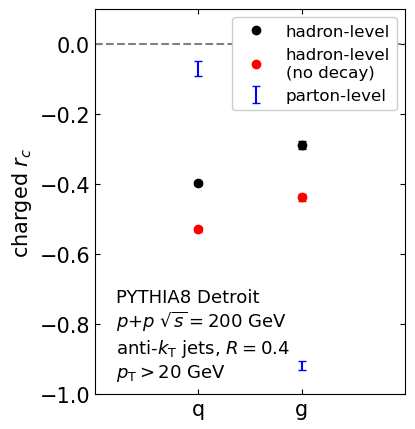

In [31]:
fig=plt.figure(figsize=(4,5))
plt.plot([0,1], rc_array, ls='none', label='hadron-level', marker='o', color='k')
plt.plot([0,1], nodecay_rc_array, ls='none', label='hadron-level\n(no decay)', marker='o', color='r')
plt.errorbar([0,1], rc_array, yerr=rc_err_array, capsize=3, ls='none', color='k')
plt.errorbar([0,1], nodecay_rc_array, yerr=nodecay_rc_err_array, capsize=3, ls='none', color='r')
plt.errorbar([0,1], parton_rc_array, yerr=parton_rc_err_array, capsize=3, ls='none', label='parton-level', color='b')
plt.axhline(y=0.0, color='grey', linestyle='--')
#plt.text(20,0.025, 'STAR Preliminary', color='r', fontstyle='italic', fontsize=15)
#plt.xlabel('matched parton PID', fontsize=15)
plt.text(-0.8,-0.95,'PYTHIA8 Detroit\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $R=0.4$\n$p_{\mathrm{T}} > 20$ GeV', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged $r_c$', fontsize=15)
plt.ylim(-1,0.1)
plt.xlim(-1,2)
plt.xticks([0,1],['q','g'], fontsize=15)
plt.yticks(fontsize=15)
plt.legend(fontsize=12, loc='upper right', framealpha=1)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')